# 托卡马克粒子轨道探索器 — 演示

本笔记本展示以下内容：
1. 托卡马克磁场中 Boris 推进器的能量守恒。
2. 磁镜磁场中磁矩的守恒行为。
3. Boris 算法的二阶收敛性验证。
4. 香蕉轨道（导心近似）。

In [1]:
import os
import sys
sys.path.insert(0, os.path.abspath('..'))

%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

# 设置中文字体，按常见系统字体依次尝试
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "WenQuanYi Micro Hei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

from src.particles import Particle
from src.fields import TokamakField, MirrorField
from src.integrators import boris_integrate, guiding_center_integrate
from src.diagnostics import kinetic_energy, magnetic_moment

PROTON_MASS = 1.6726219e-27
PROTON_CHARGE = 1.6021766e-19
E = lambda x, y, z: np.zeros(3)

## 托卡马克磁场

对于圆截面、大环径比托卡马克，磁场可写为：
$$B_\phi = B_0 \frac{R_0}{R}, \quad B_\theta = \frac{r}{R q(r)} B_\phi$$

其中 $B_\phi$ 为环向场，$B_\theta$ 为极向场，$q(r)$ 为安全因子剖面。

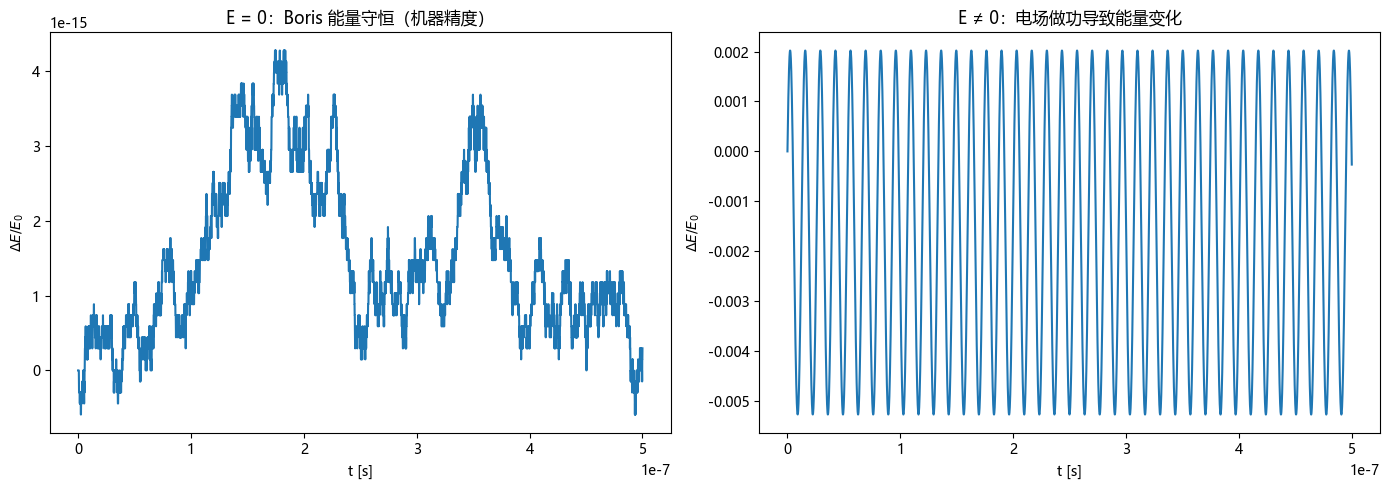

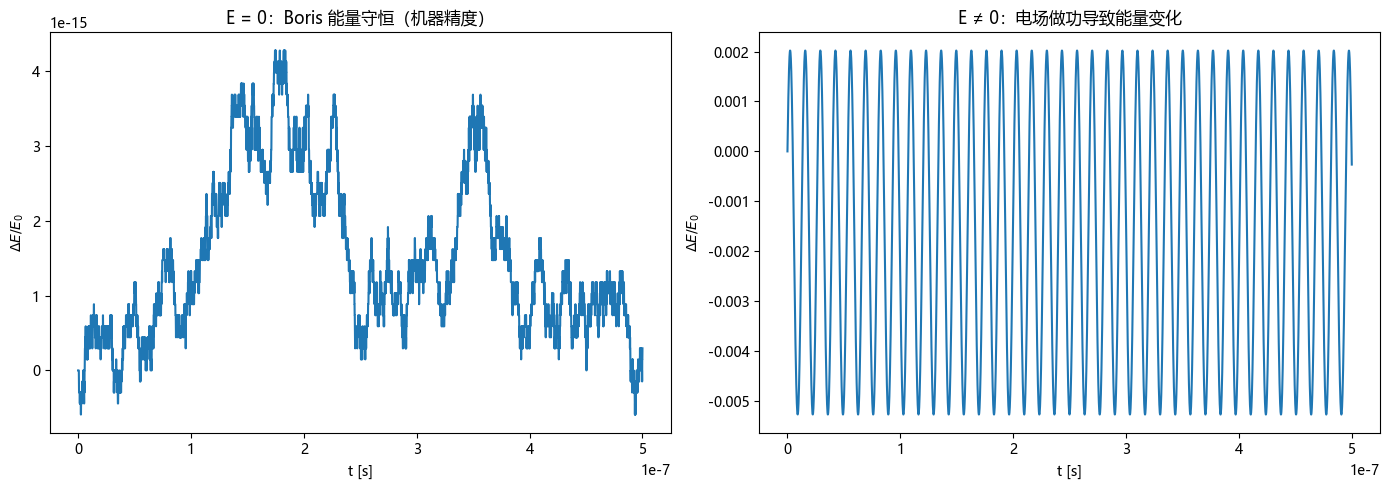

In [2]:
field = TokamakField(B0=5.0, R0=10.0, a=1.0, q0=1.0, q1=2.0)
v = np.array([1e5, 0.0, 5e4])
p = Particle(PROTON_CHARGE, PROTON_MASS, np.array([10.2, 0.0, 0.0]), v)

# E=0：Boris 保持 |v|，能量误差仅为舍入噪声
result_zero_e = boris_integrate(field, E, p, dt=1e-10, n_steps=5000)
energies_zero = np.array([kinetic_energy(vv, PROTON_MASS) for vv in result_zero_e["velocity"]])

# E≠0：电场做功导致能量变化
e_field = lambda x, y, z: np.array([1000.0, 0.0, 0.0])
result_e = boris_integrate(field, e_field, p, dt=1e-10, n_steps=5000)
energies_e = np.array([kinetic_energy(vv, PROTON_MASS) for vv in result_e["velocity"]])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(result_zero_e["times"], (energies_zero - energies_zero[0]) / energies_zero[0])
axes[0].set_xlabel("t [s]")
axes[0].set_ylabel(r"$\Delta E / E_0$")
axes[0].set_title("E = 0：Boris 能量守恒（机器精度）")

axes[1].plot(result_e["times"], (energies_e - energies_e[0]) / energies_e[0])
axes[1].set_xlabel("t [s]")
axes[1].set_ylabel(r"$\Delta E / E_0$")
axes[1].set_title("E ≠ 0：电场做功导致能量变化")

fig.tight_layout()
fig

## 磁镜磁场

轴上磁场强度随轴向位置变化：
$$B_z(z) = B_0 \left(1 + b_m \frac{z^2}{L^2}\right)$$

由磁场无散条件 $\nabla \cdot \mathbf{B} = 0$ 可导出径向磁场：
$$B_r(r,z) = -\frac{r}{2} \frac{dB_z}{dz}$$

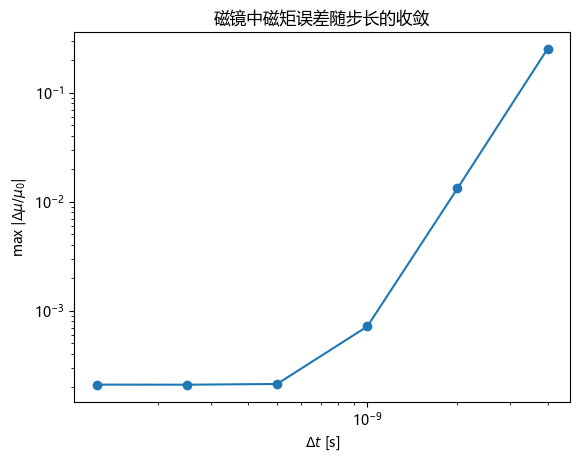

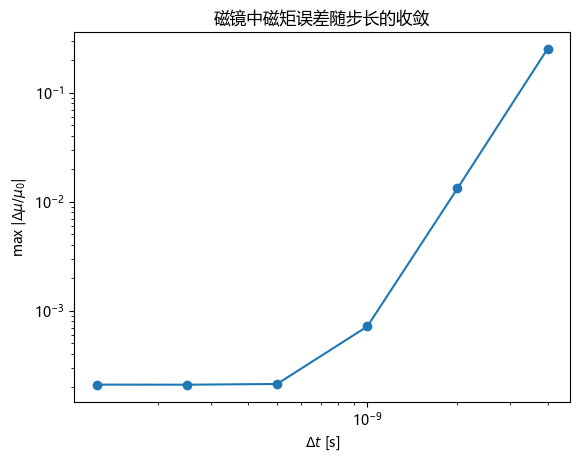

In [3]:
field = MirrorField(B0=1.0, bm=4.0, L=1.0)
v = np.array([1e4, 0.0, 5e4])
p = Particle(PROTON_CHARGE, PROTON_MASS, np.array([0.01, 0.0, 0.0]), v)

# 比较不同时间步长下的最大磁矩相对误差，区分数值漂移与物理振荡
dt_list = [4e-9, 2e-9, 1e-9, 5e-10, 2.5e-10, 1.25e-10]
max_errors = []
for dt in dt_list:
    result = boris_integrate(field, E, p, dt=dt, n_steps=5000)
    traj = result["trajectory"]
    vel = result["velocity"]
    mus = np.array([magnetic_moment(vv, field, *xx) for vv, xx in zip(vel, traj)])
    max_errors.append(np.max(np.abs((mus - mus[0]) / mus[0])))

fig, ax = plt.subplots()
ax.loglog(dt_list, max_errors, "o-")
ax.set_xlabel(r"$\Delta t$ [s]")
ax.set_ylabel(r"max $|\Delta \mu / \mu_0|$")
ax.set_title("磁镜中磁矩误差随步长的收敛")
fig

## Boris 算法收敛性

Boris 推进器具有二阶精度。下面以高分辨率计算结果作为参考，比较不同时间步长下最终位置的误差。

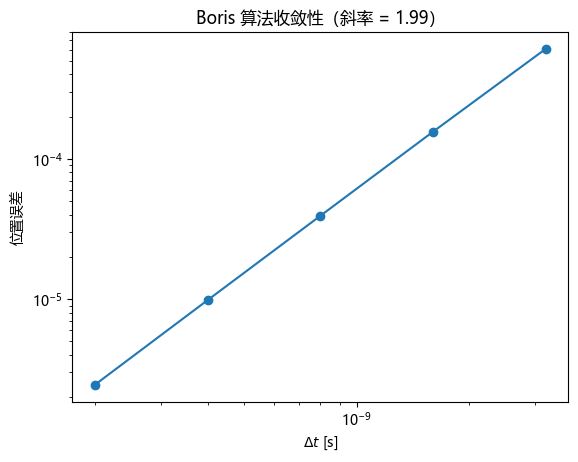

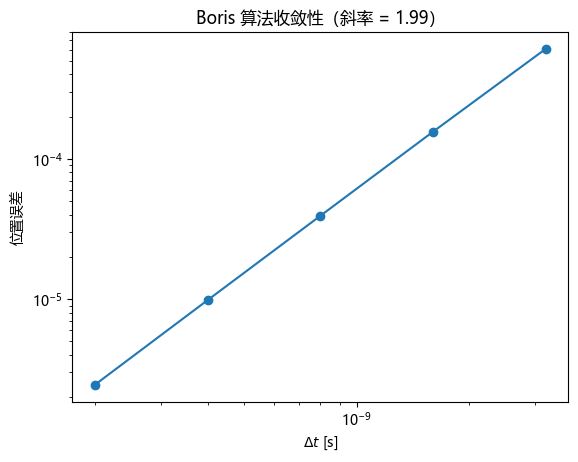

In [4]:
from src.diagnostics import convergence_test

field = MirrorField(B0=1.0, bm=2.0, L=1.0)
v = np.array([1e5, 0.0, 5e4])
p = Particle(PROTON_CHARGE, PROTON_MASS, np.array([0.01, 0.0, 0.0]), v)
# 使用更多步长点和更细的参考解，减少参考误差和相位误差的影响
dt_list = [2e-10, 4e-10, 8e-10, 1.6e-9, 3.2e-9]
result = convergence_test(field, E, p, dt_ref=2.5e-11, n_steps_ref=32000, dt_list=dt_list)

slope = np.polyfit(np.log(result["dt_list"]), np.log(result["errors"]), 1)[0]
fig, ax = plt.subplots()
ax.loglog(result["dt_list"], result["errors"], "o-")
ax.set_xlabel(r"$\Delta t$ [s]")
ax.set_ylabel("位置误差")
ax.set_title(f"Boris 算法收敛性（斜率 = {slope:.2f}）")
fig

## 香蕉轨道（导心近似）

在托卡马克中，被磁场镜效应捕获的粒子会形成香蕉轨道。由于 Boris 全粒子推进在长时间内会出现磁矩漂移，这里使用导心近似（假设磁矩守恒）来展示完整的香蕉轨道。

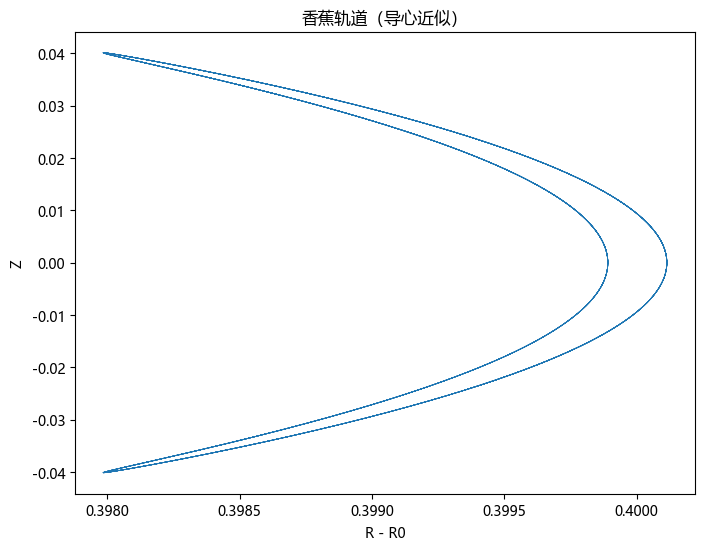

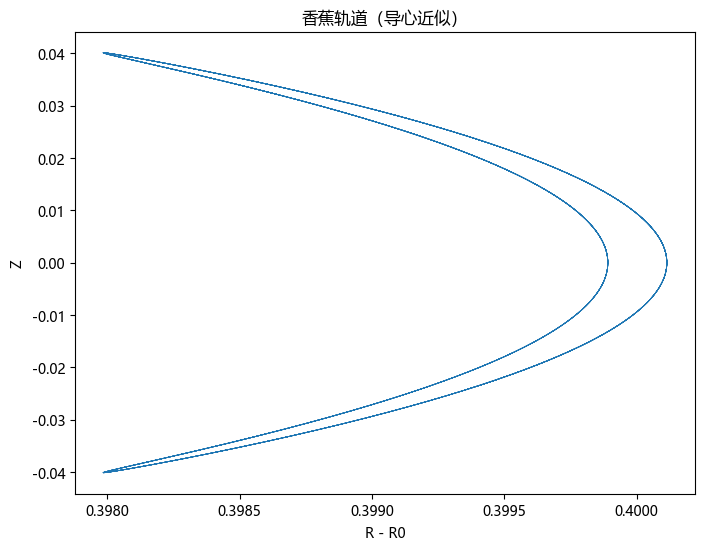

In [5]:
field = TokamakField(B0=5.0, R0=10.0, a=1.0, q0=1.0, q1=2.0)
# 被磁镜效应捕获的粒子，初始位置稍远离磁轴使香蕉宽度可见
v = np.array([1e5, 0.0, 5e4])
p = Particle(PROTON_CHARGE, PROTON_MASS, np.array([10.4, 0.0, 0.0]), v)

# 导心近似用于展示完整香蕉轨道；Boris 全轨道因 μ 漂移不适合直接跑完整 bounce。
result_gc = guiding_center_integrate(field, p, dt=1e-7, n_steps=300000)

R_g = np.sqrt(result_gc["trajectory"][:, 0] ** 2 + result_gc["trajectory"][:, 1] ** 2)
Z_g = result_gc["trajectory"][:, 2]

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(R_g - 10.0, Z_g, lw=0.6)
ax.set_xlabel("R - R0")
ax.set_ylabel("Z")
ax.set_title("香蕉轨道（导心近似）")
fig